In [1]:
from dask.distributed import Client
from hats_import.pipeline import pipeline_with_client
from hats_import.catalog.arguments import ImportArguments
from hats_import.catalog.file_readers import CsvReader

In [2]:
args = ImportArguments(
    sort_columns="object_id",
    ra_column="ra",
    dec_column="dec",
    input_file_list=["LaStBeRu_watchlist_LSST_grades.csv"],
    file_reader=CsvReader(
        comment="#",
        header=0,
        column_names=["object_id","ra","dec","type_label","original_source","redshift","redshift_error","redshift_label","extra_info"],
        skipinitialspace=True,
    ),
    output_artifact_name="lastberu_test",
    output_path="./output",
)

In [3]:
with Client(n_workers=1) as client:
    pipeline_with_client(args, client)

Catalog: Planning  :   0%|          | 0/4 [00:00<?, ?it/s]

Catalog: Mapping   :   0%|          | 0/1 [00:00<?, ?it/s]

Catalog: Binning   :   0%|          | 0/2 [00:00<?, ?it/s]

Catalog: Splitting :   0%|          | 0/1 [00:00<?, ?it/s]

Catalog: Reducing  :   0%|          | 0/12 [00:00<?, ?it/s]

Catalog: Finishing :   0%|          | 0/10 [00:00<?, ?it/s]

In [5]:
import lsdb
from upath import UPath
from dask.distributed import Client
from lsdb.streams import CatalogStream
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
import logging

logging.getLogger().setLevel(logging.WARNING)
logging.getLogger("distributed").setLevel(logging.WARNING)

In [6]:
plt.rcParams.update(
    {
        "axes.titlesize": 16,
        "axes.labelsize": 15,
        "xtick.labelsize": 13,
        "ytick.labelsize": 13,
        "legend.fontsize": 13,
        "figure.titlesize": 18,
    }
)

In [7]:
dp2_path = UPath("/rubin/lsdb_data/object_collection")

dp2 = lsdb.open_catalog(dp2_path, columns=["coord_ra", "coord_dec"])
dp2

,coord_ra,coord_dec
npartitions=8840,,
"Order: 8, Pixel: 10240",double[pyarrow],double[pyarrow]
...,...,...
"Order: 5, Pixel: 12283",...,...
"Order: 5, Pixel: 12284",...,...


In [9]:
lastberu = lsdb.open_catalog(
    "./output/lastberu_test",
    columns=["ra", "dec"],
)
lastberu

,ra,dec
npartitions=12,,
"Order: 0, Pixel: 0",double[pyarrow],double[pyarrow]
...,...,...
"Order: 0, Pixel: 10",...,...
"Order: 0, Pixel: 11",...,...


In [10]:
xmatch = dp2.crossmatch(lastberu, suffix_method="overlapping_columns")
xmatch

/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/lsdb/operations/functions/crossmatch_catalog_data.py:357: RuntimeWarning: Right catalog does not have a margin cache. Results may be incomplete and/or inaccurate.
  warnings.warn(


,coord_ra,coord_dec,ra,dec,_dist_arcsec
npartitions=1228,,,,,
"Order: 8, Pixel: 10862",double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow]
...,...,...,...,...,...
"Order: 5, Pixel: 12281",...,...,...,...,...
"Order: 5, Pixel: 12282",...,...,...,...,...


In [11]:
# Write a simple map_partitions function to count resulting matches
def count_matches(df):
    return {"n_matches": len(df)}


matches_by_partition = xmatch.map_partitions(count_matches)

In [12]:
# Define a client, and .compute() the match result
with Client(n_workers=4, threads_per_worker=1, memory_limit="4GB") as client:
    print(f"Dask dashboard: {client.dashboard_link}")
    match_df = matches_by_partition.compute()
    client.close()

Dask dashboard: https://jnisbet.nb.data.lsst.cloud/nb/user/jnisbet/proxy/8787/status


Computing Catalog:   0%|          | 0/1228 [00:00<?, ?it/s]

In [13]:
print(f"Number of Matches: {match_df["n_matches"].sum()}")

Number of Matches: 2324


In [ ]:
ra_dec_df = xmatch.to_dask_dataframe()[["coord_ra", "coord_dec"]]

with Client(n_workers=4, threads_per_worker=1, memory_limit="4GB") as client:
    matched_coordinates = ra_dec_df.compute()

print(matched_coordinates)

In [74]:
from astropy.coordinates import SkyCoord
import astropy.units as u
from lsst.rsp import get_tap_service
import pandas as pd
import pickle
from tqdm import tqdm

tap_service = get_tap_service("tap")

DIA_OBJECT_TABLE = "dp2.DiaObject"
RADIUS_ARCSEC = 40.0
RADIUS_DEG = RADIUS_ARCSEC / 3600.0

CSV_PATH = "lastberuXdp2_coords.csv"
PICKLE_PATH = "lastberu_dia_objects.pkl"
BATCH_SIZE = 100

targets = pd.read_csv(CSV_PATH)
targets.columns = targets.columns.astype(str).str.strip()

target_coords = SkyCoord(
  targets["coord_ra"].to_numpy() * u.deg,
  targets["coord_dec"].to_numpy() * u.deg
)

# Guardamos temporalmente las coincidencias por índice de target
matches = {i: [] for i in range(len(targets))}

for start in tqdm(
  range(0, len(targets), BATCH_SIZE),
  desc="Consultas TAP"
):
  stop = min(start + BATCH_SIZE, len(targets))

  clauses = []
  for ra, dec in zip(
      targets["coord_ra"].iloc[start:stop],
      targets["coord_dec"].iloc[start:stop]
  ):
      clauses.append(
          f"""
          CONTAINS(
              POINT('ICRS', ra, dec),
              CIRCLE(
                  'ICRS',
                  {ra:.15g},
                  {dec:.15g},
                  {RADIUS_DEG:.15g}
              )
          ) = 1
          """
      )

  query = f"""
  SELECT diaObjectId, ra, dec
  FROM {DIA_OBJECT_TABLE}
  WHERE {" OR ".join(clauses)}
  """

  job = tap_service.submit_job(query)
  job.run()
  job.wait(phases=["COMPLETED", "ERROR"])

  if job.phase == "ERROR":
      job.raise_if_error()

  batch_objects = job.fetch_result().to_table().to_pandas()

  if batch_objects.empty:
      continue

  object_coords = SkyCoord(
      batch_objects["ra"].to_numpy() * u.deg,
      batch_objects["dec"].to_numpy() * u.deg
  )
 
  idx_object, idx_target, separations, _ = (
      target_coords[start:stop].search_around_sky(
          object_coords,
          RADIUS_ARCSEC * u.arcsec
      )
  )

  for i_target, i_object, separation in zip(
      idx_target, idx_object, separations
  ):
      row = batch_objects.iloc[int(i_object)].to_dict()
      row["sep_arcsec"] = separation.arcsec
      matches[start + int(i_target)].append(row)

# Reconstruir el mismo diccionario target -> DataFrame
objects_by_target = {}

for i, target in targets.iterrows():
  objects_by_target[target["object_id"]] = pd.DataFrame(
      matches[i],
      columns=["diaObjectId", "ra", "dec", "sep_arcsec"]
  )

with open(PICKLE_PATH, "wb") as f:
  pickle.dump(objects_by_target, f)

print(f"Guardado en {PICKLE_PATH}")

Consultas TAP: 100%|██████████| 24/24 [10:45<00:00, 26.92s/it]


Guardado en lastberu_dia_objects.pkl


Text(0.5, 1.0, 'Objects nearby StrongLensing systems ')

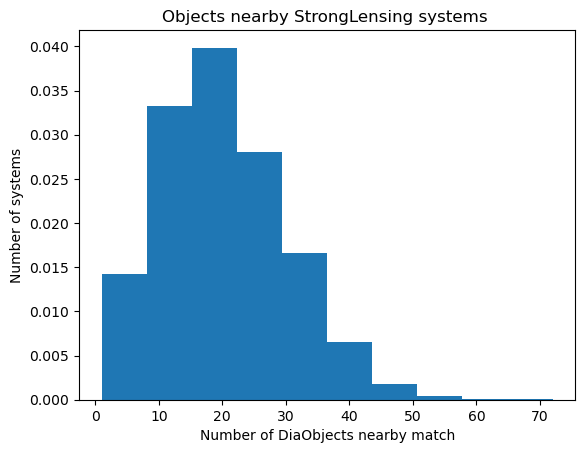

In [68]:
import matplotlib.pyplot as plt
obj = list(objects_by_target.values())
plt.hist([len(o) for o in obj], density=True)
plt.xlabel("Number of DiaObjects nearby match")
plt.ylabel("Number of systems")
plt.title("Objects nearby StrongLensing systems ")

In [27]:
obj_val = [len(o) for o in obj]
pd.Series(obj_val).value_counts()

0     1164
1      408
2      239
3      104
4       89
5       56
6       47
7       42
8       29
9       23
11      19
10      13
13      11
14       8
15       8
12       6
16       3
17       2
23       2
18       2
36       2
19       2
38       1
25       1
33       1
29       1
20       1
21       1
39       1
31       1
Name: count, dtype: int64

In [76]:
import pandas as pd
lastberu = pd.read_csv("LaStBeRu_watchlist_LSST_grades.csv")
lastberu.head()

,object_id,ra,dec,type_label,original_source,redshift,redshift_error,redshift_label,extra_info
0,LaStBeRu_J000001.1-350334.9,0.00471,-35.05971,Candidate SL system,Gioia et al. (1990) - doi:10.1086/191426,0.508000,-1.00000,NaN,"vetting_grade=nan,vetting_grade_survey=nan,Ori..."
1,LaStBeRu_J000001.2+051908.6,0.00504,5.31906,Candidate SL system,Lopes et al. (2004) - doi:10.1086/423038,0.850000,0.33321,photometric,"vetting_grade=E,vetting_grade_survey=Legacy,Or..."
2,LaStBeRu_J000002.2+085518.4,0.00925,8.92179,Candidate SL system,Lopes et al. (2004) - doi:10.1086/423038,-1.000000,-1.00000,NaN,"vetting_grade=E,vetting_grade_survey=Legacy,Or..."
3,LaStBeRu_J000006.0+081629.7,0.02512,8.27492,Candidate SL system,Lopes et al. (2004) - doi:10.1086/423038,-1.000000,-1.00000,NaN,"vetting_grade=E,vetting_grade_survey=Legacy,Or..."
4,LaStBeRu_J000006.1+213829.4,0.02542,21.64150,Candidate SL system,Huang et al. (2021) - arXiv:2005.04730,0.502973,-1.00000,spectroscopic,"vetting_grade=D,vetting_grade_survey=Legacy,Or..."


In [77]:
lsb_match = lastberu[lastberu["object_id"].isin(objects_by_target.keys())]

In [78]:
obj_id = objects_by_target.keys(), 
obj_n = list(objects_by_target.values())

In [79]:
lsb_match=lastberu[lastberu["object_id"].isin(objects_by_target)].copy()
lsb_match["dia_objects"]=lsb_match["object_id"].map(objects_by_target)
lsb_match["vetting_grade"] = lsb_match["extra_info"].str[14]

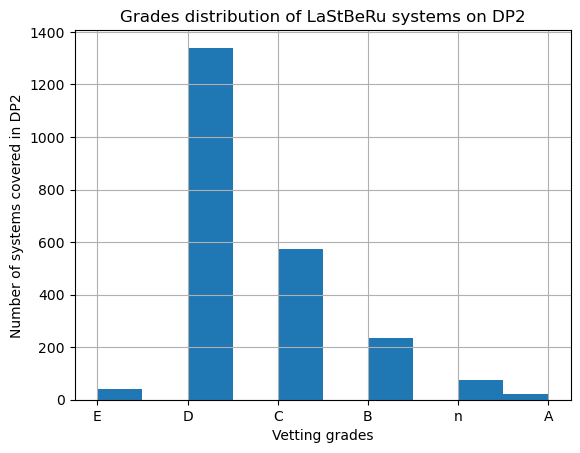

In [82]:
lsb_match["vetting_grade"].hist()
plt.xlabel("Vetting grades")
plt.ylabel("Number of systems covered in DP2")
plt.title("Grades distribution of LaStBeRu systems on DP2")
plt.savefig("grades_distrib_on_DP2.png")

In [57]:
A_matchs = lsb_match[lsb_match["vetting_grade"].isin(["A"])]
A_matchs

,object_id,ra,dec,type_label,original_source,redshift,redshift_error,redshift_label,extra_info,dia_objects,vetting_grade
478,LaStBeRu_J001309.6+004003.5,3.29013,0.66765,Confirmed galaxy,Canameras et al. (2021) - arXiv:2107.07829 § J...,0.692968,0.000254,spectroscopic,"vetting_grade=A,vetting_grade_survey=HSC,Origi...","Empty DataFrame Columns: [diaObjectId, ra, dec...",A
549,LaStBeRu_J001457.8+013701.2,3.74067,1.61699,Candidate SL system,Stein et al. (2021) - arXiv:2110.00023 § Storf...,0.330000,0.020372,photometric,"vetting_grade=A,vetting_grade_survey=HSC,Origi...",diaObjectId ra dec sep_arcse...,A
573,LaStBeRu_J001542.8-463611.0,3.92831,-46.60305,Candidate galaxy,Jacobs et al. (2019) - arXiv:1905.10522 § Mous...,0.517126,0.044720,photometric,"vetting_grade=A,vetting_grade_survey=DES,Origi...","Empty DataFrame Columns: [diaObjectId, ra, dec...",A
1466,LaStBeRu_J003857.5-074523.0,9.73950,-7.75640,Candidate SL system,Huang et al. (2021) - arXiv:2005.04730,0.441152,0.000073,spectroscopic,"vetting_grade=A,vetting_grade_survey=Legacy,Or...","Empty DataFrame Columns: [diaObjectId, ra, dec...",A
1905,LaStBeRu_J004958.4+022715.9,12.49312,2.45441,Candidate SL system,Stein et al. (2021) - arXiv:2110.00023 § Storf...,0.438466,0.224191,photometric,"vetting_grade=A,vetting_grade_survey=HSC,Origi...","Empty DataFrame Columns: [diaObjectId, ra, dec...",A
2537,LaStBeRu_J010519.9+014459.1,16.33288,1.74975,Candidate SL system,Moustakas et al. (2012) - adsabs:2012hst..prop...,0.952072,0.369475,photometric,"vetting_grade=A,vetting_grade_survey=HSC,Origi...","Empty DataFrame Columns: [diaObjectId, ra, dec...",A
3833,LaStBeRu_J013639.2+000818.2,24.16316,0.13838,Confirmed galaxy,Moraes et al. (2014) - adsabs:2014RMxAC..44..2...,0.344125,0.000000,spectroscopic,"vetting_grade=A,vetting_grade_survey=HSC,Origi...","Empty DataFrame Columns: [diaObjectId, ra, dec...",A
4117,LaStBeRu_J014404.0-000746.4,26.01675,-0.12955,Candidate galaxy,Jacobs et al. (2019) - arXiv:1905.10522 § Mous...,0.563734,0.000162,spectroscopic,"vetting_grade=A,vetting_grade_survey=HSC,Origi...","Empty DataFrame Columns: [diaObjectId, ra, dec...",A
33095,LaStBeRu_J223353.8+015721.7,338.47414,1.95603,Confirmed group/cluster,Canameras et al. (2021) - arXiv:2107.07829 § M...,0.252119,0.012454,photometric,"vetting_grade=A,vetting_grade_survey=HSC,Origi...",diaObjectId ra dec sep_arc...,A
33288,LaStBeRu_J224201.2+022810.5,340.50494,2.46960,Candidate galaxy,Moustakas et al. (2012) - adsabs:2012hst..prop...,0.443319,0.000099,spectroscopic,"vetting_grade=A,vetting_grade_survey=HSC,Origi...","Empty DataFrame Columns: [diaObjectId, ra, dec...",A


Radio: 20" | DiaObjects encontrados: 0


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


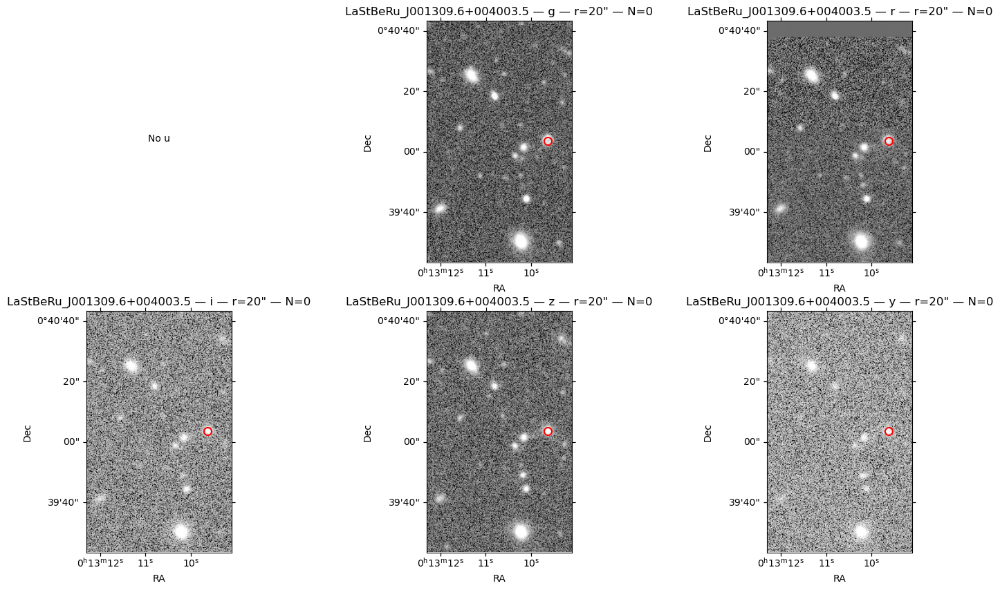

Radio: 20" | DiaObjects encontrados: 2
          diaObjectId  sep_arcsec
1  787338217698361417    0.040757
0  787338217698361578   17.768598


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout(); plt.show()


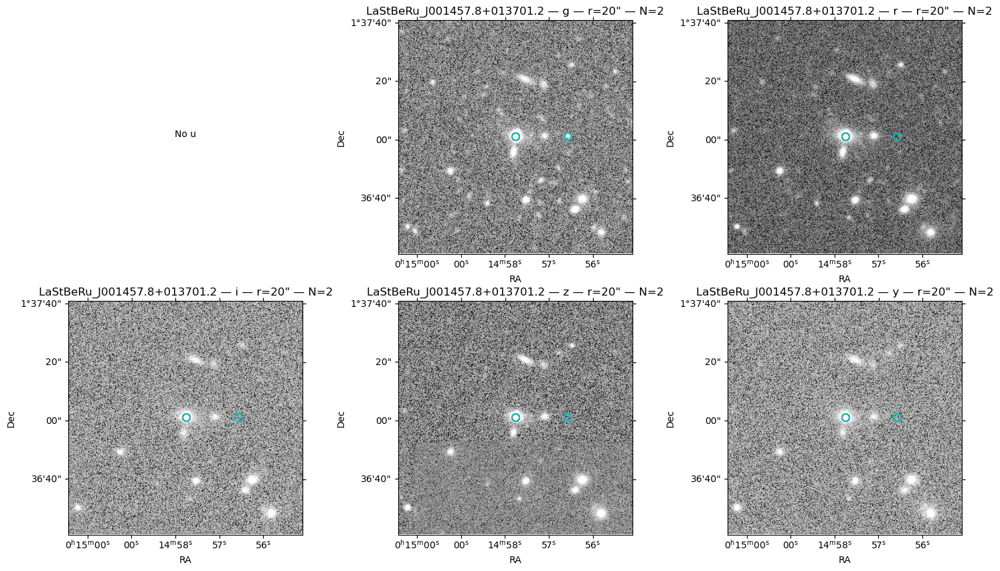

Radio: 20" | DiaObjects encontrados: 0


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


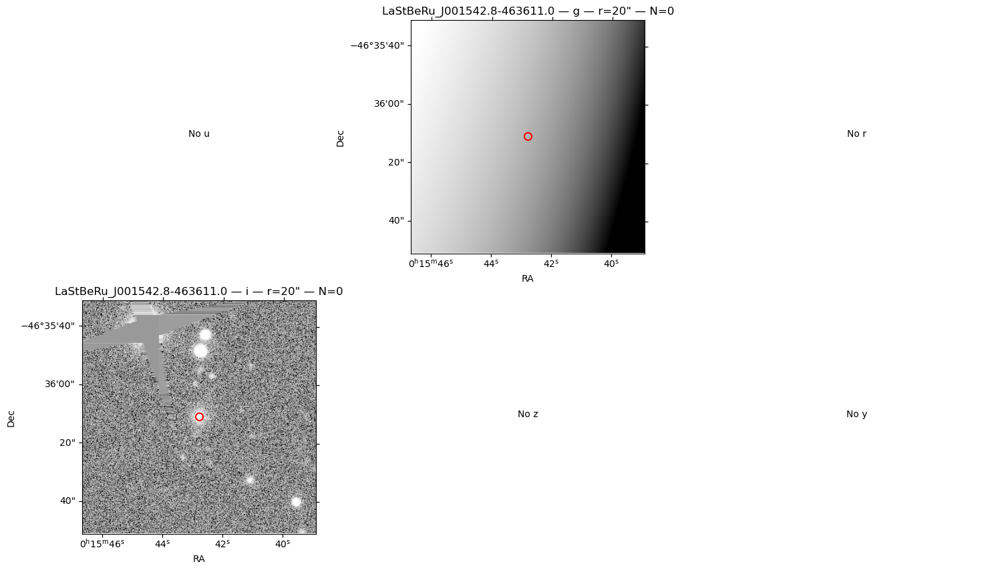

Radio: 20" | DiaObjects encontrados: 0


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


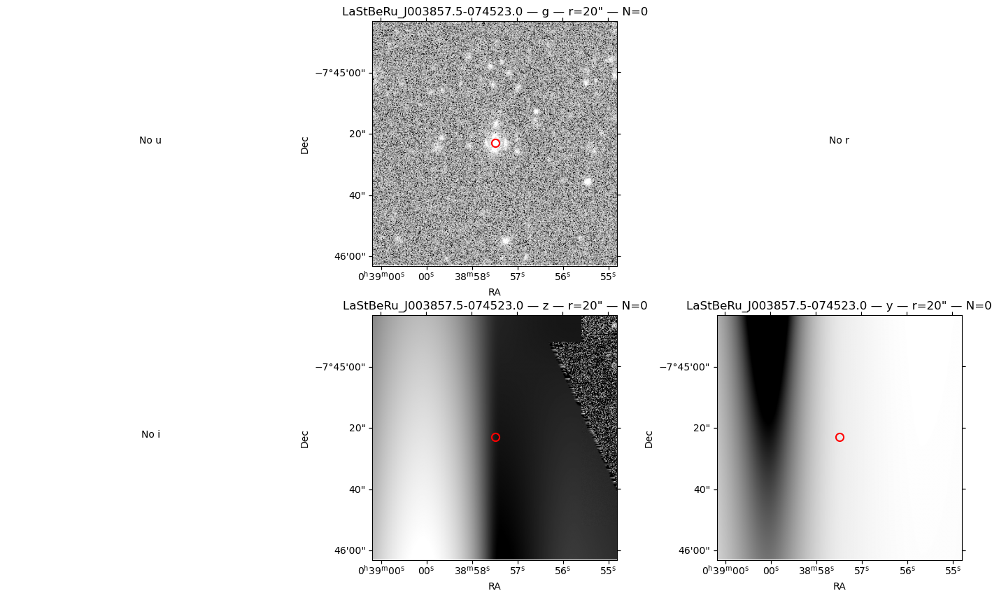

Radio: 20" | DiaObjects encontrados: 0


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout(); plt.show()


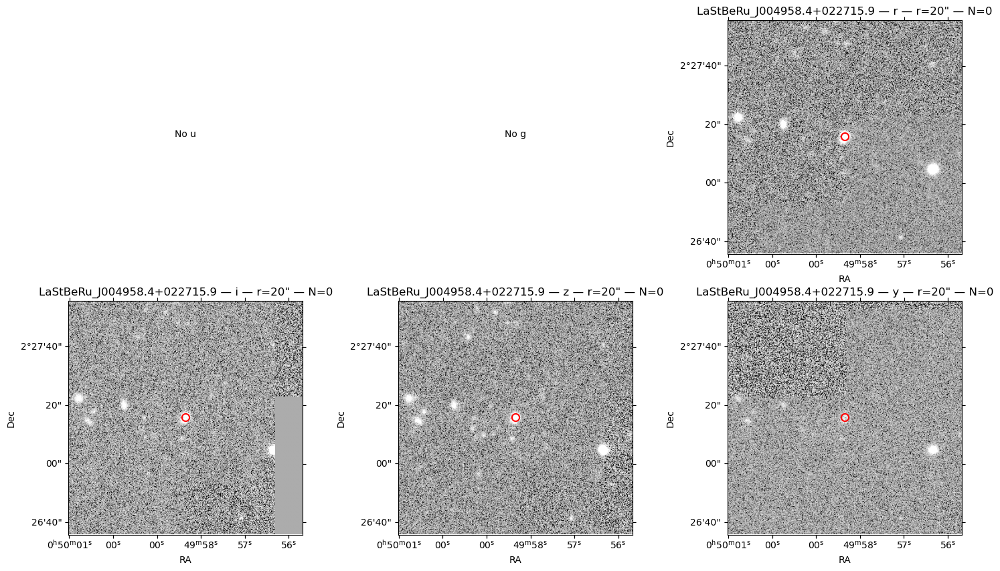

Radio: 20" | DiaObjects encontrados: 0


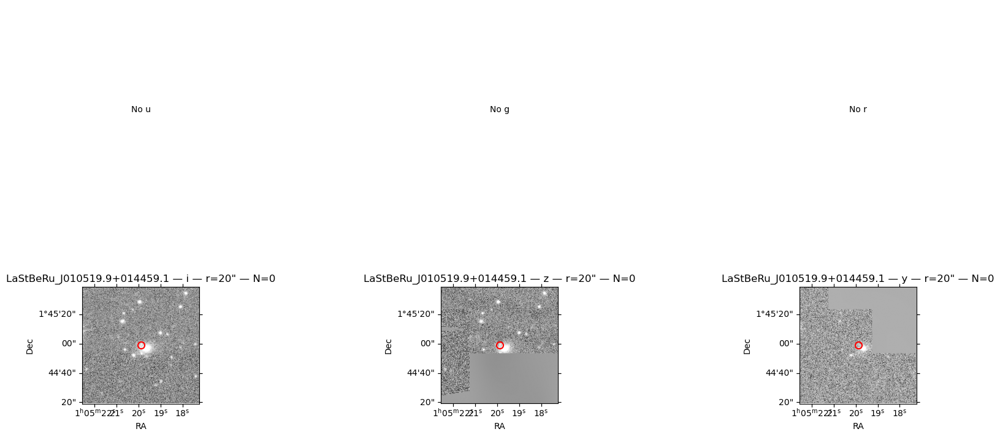

Radio: 20" | DiaObjects encontrados: 0


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


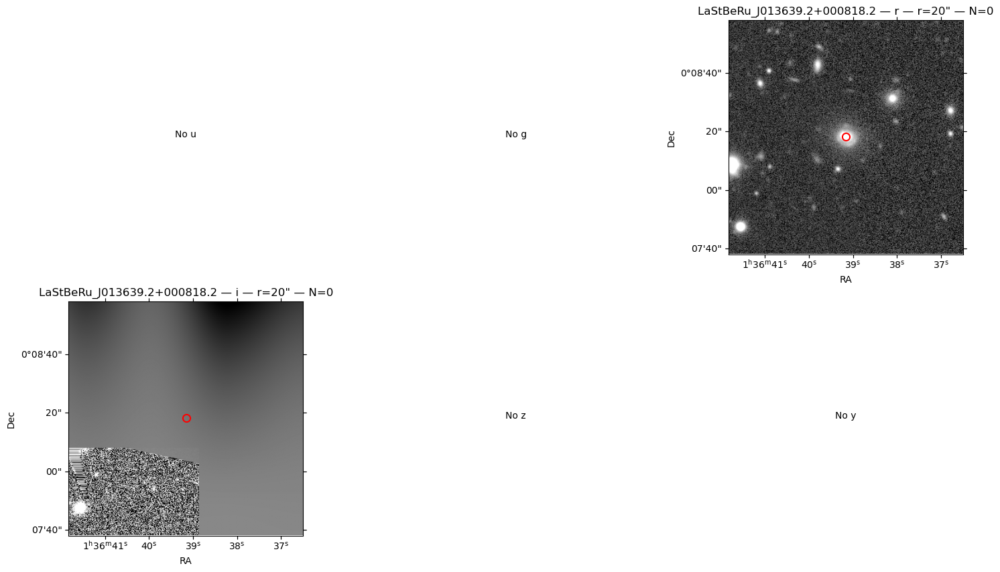

Radio: 20" | DiaObjects encontrados: 0


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


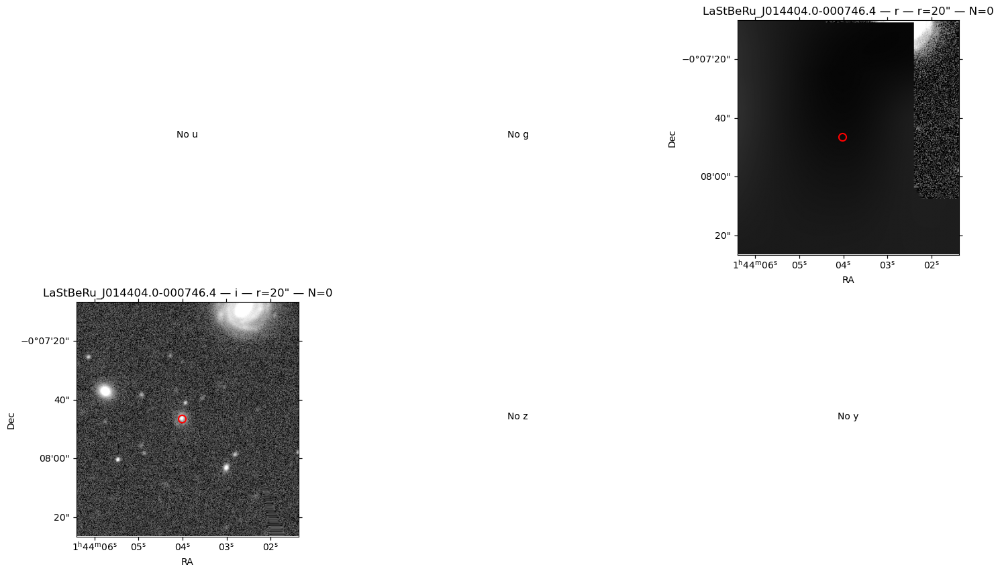

Radio: 20" | DiaObjects encontrados: 3
          diaObjectId  sep_arcsec
2  788885780314456248    0.256785
0  788885780314456445   12.995325
1  788885780314456298   13.920450


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout(); plt.show()


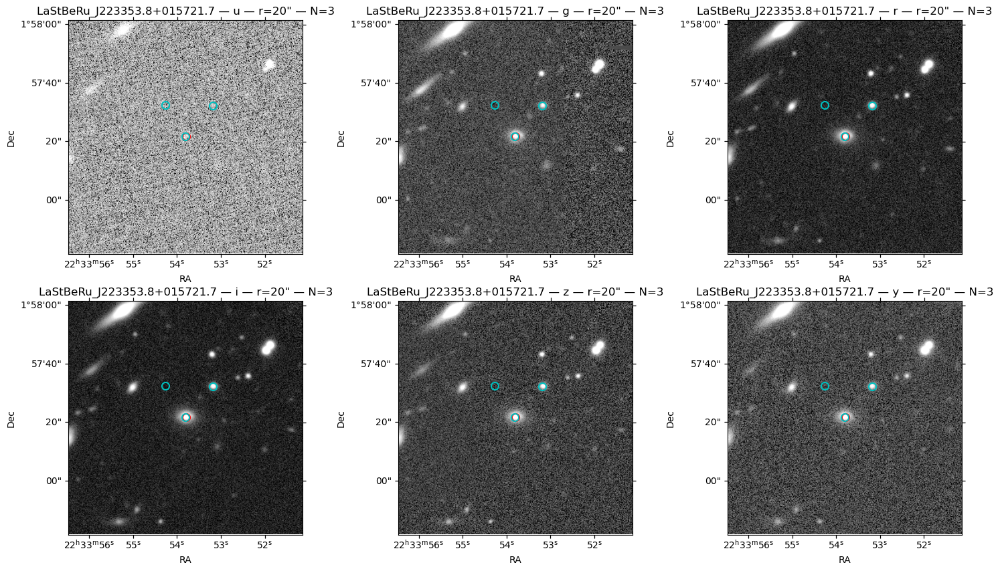

Radio: 20" | DiaObjects encontrados: 0


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


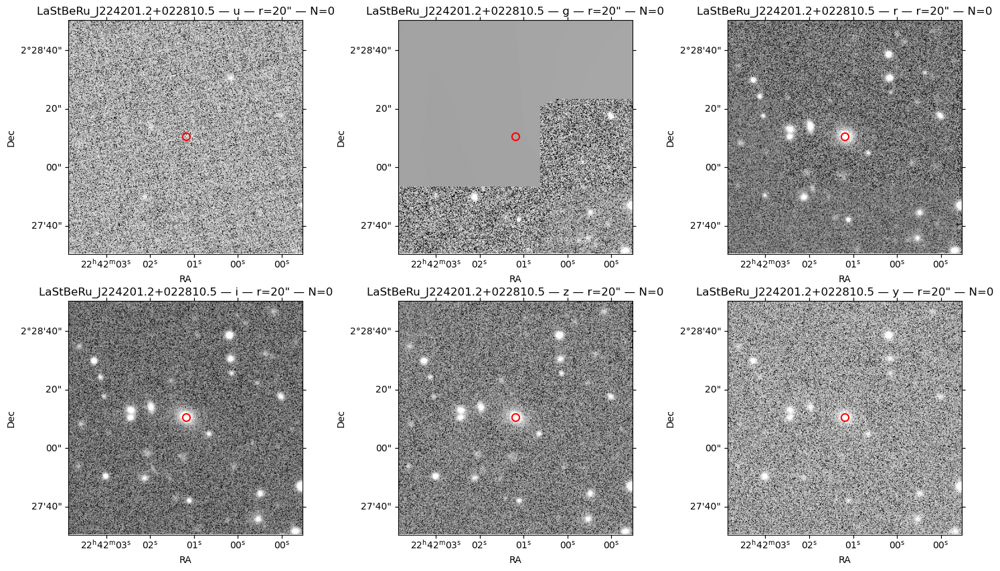

Radio: 20" | DiaObjects encontrados: 2
          diaObjectId  sep_arcsec
0  787227991657676802    0.119949
1  787227991657676801   12.460091


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


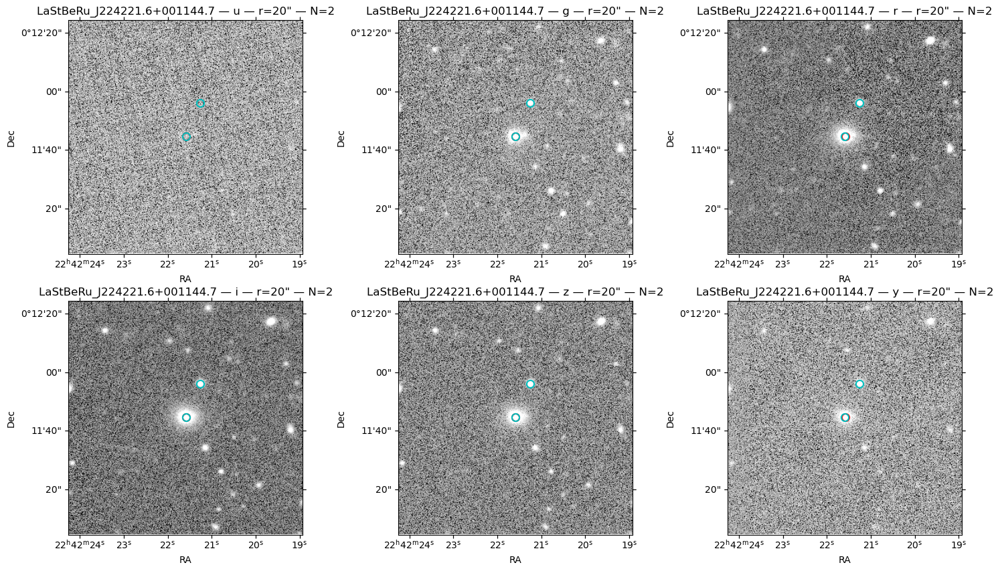

Radio: 20" | DiaObjects encontrados: 0


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


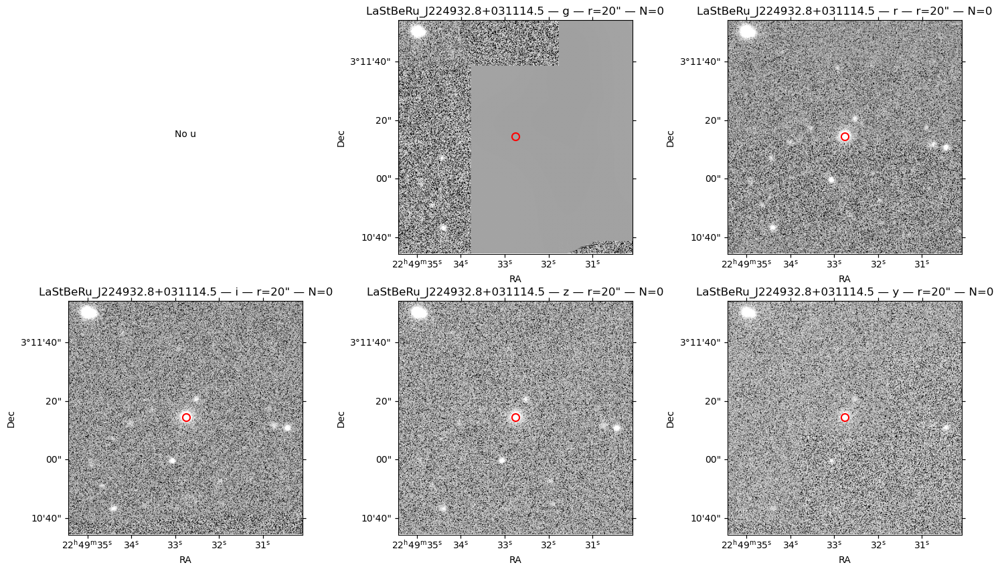

Radio: 20" | DiaObjects encontrados: 1
          diaObjectId  sep_arcsec
0  785591162441302325    0.780754


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


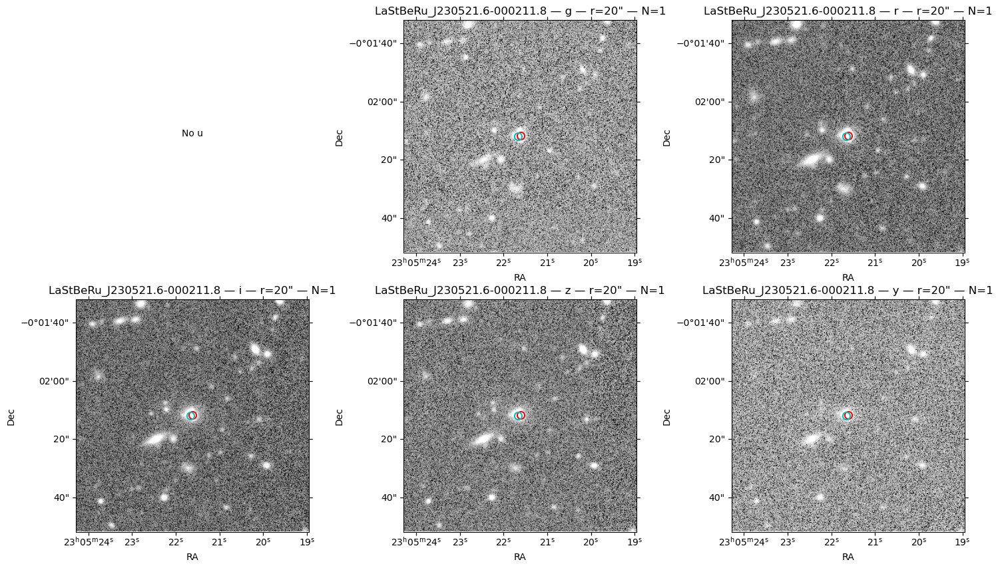

Radio: 20" | DiaObjects encontrados: 1
          diaObjectId  sep_arcsec
0  785591162441302325    0.335395


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


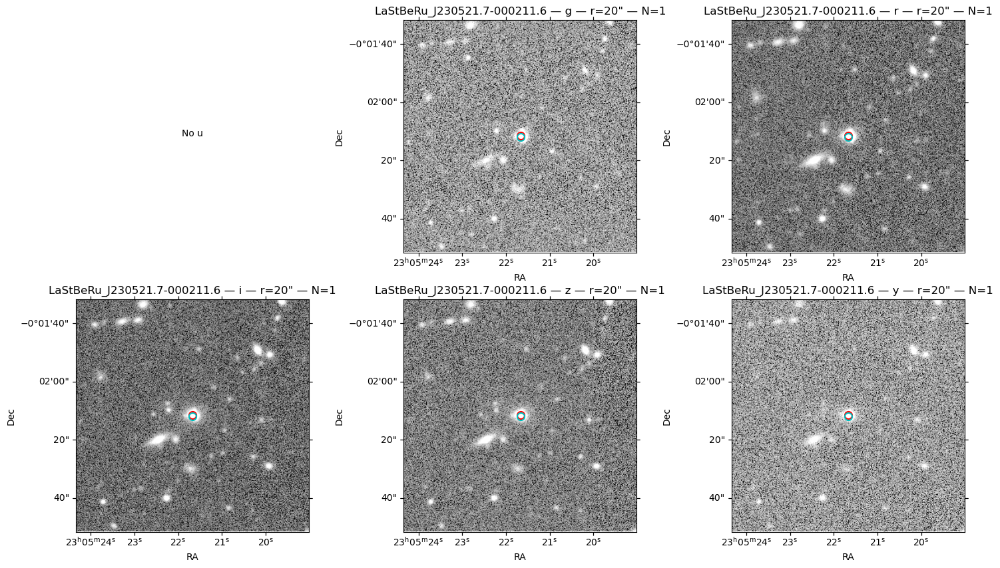

Radio: 20" | DiaObjects encontrados: 2
          diaObjectId  sep_arcsec
0  782262940744024132    0.237568
1  782262940744024328    3.355876


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


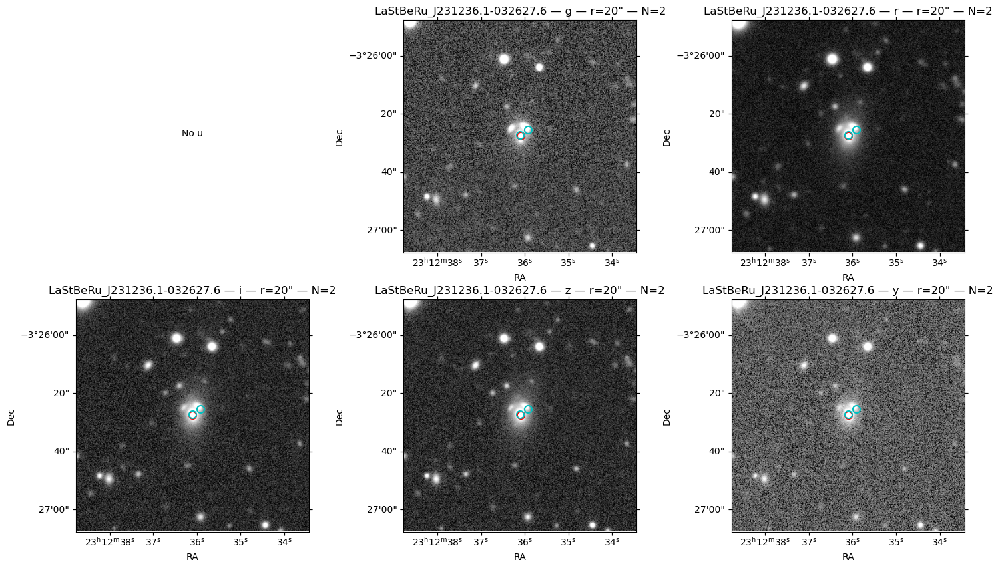

Radio: 20" | DiaObjects encontrados: 2
          diaObjectId  sep_arcsec
1  787280218459996402    9.318145
0  787280218459996403   11.118142


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


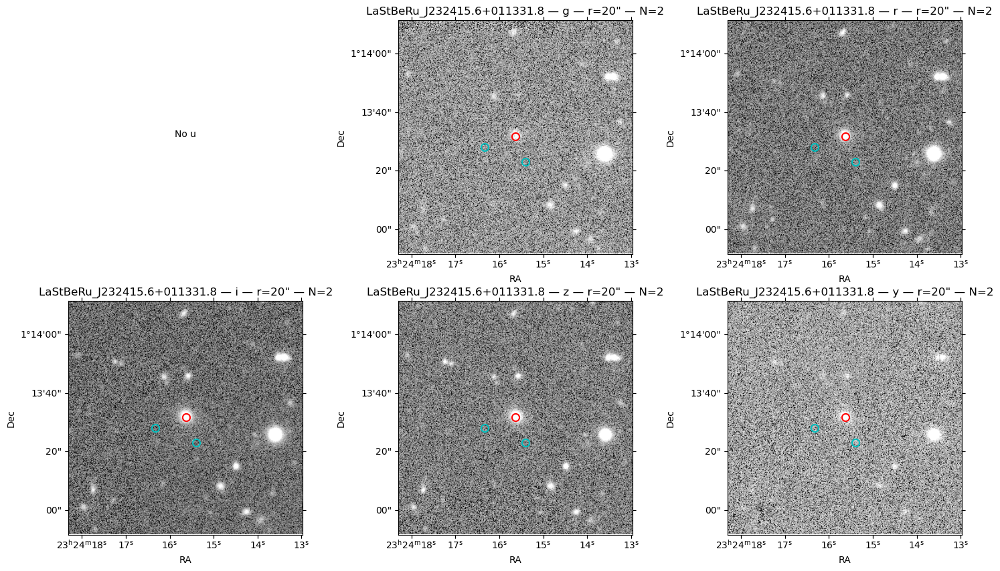

Radio: 20" | DiaObjects encontrados: 0


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout(); plt.show()


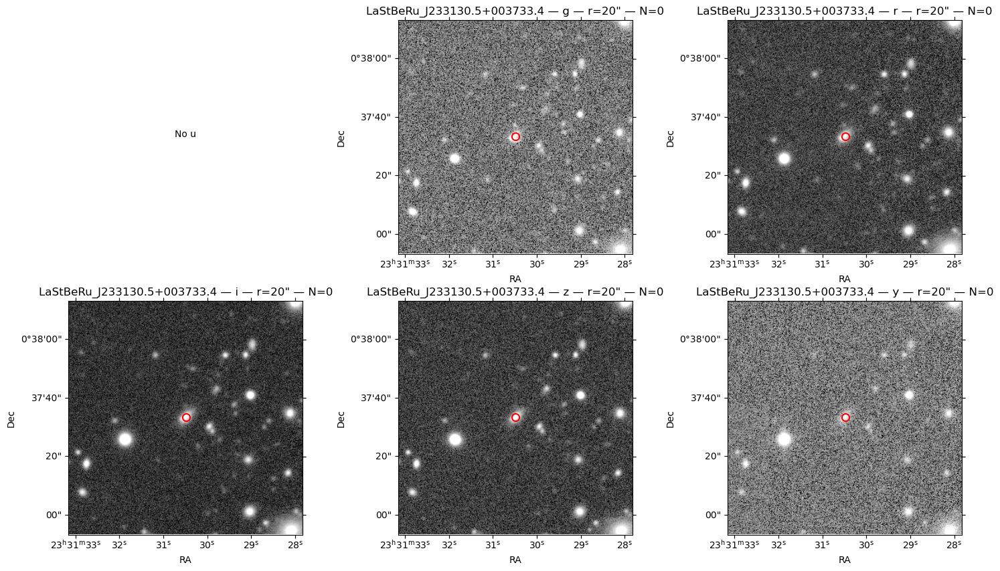

Radio: 20" | DiaObjects encontrados: 1
          diaObjectId  sep_arcsec
0  788945772417646857   18.037214


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


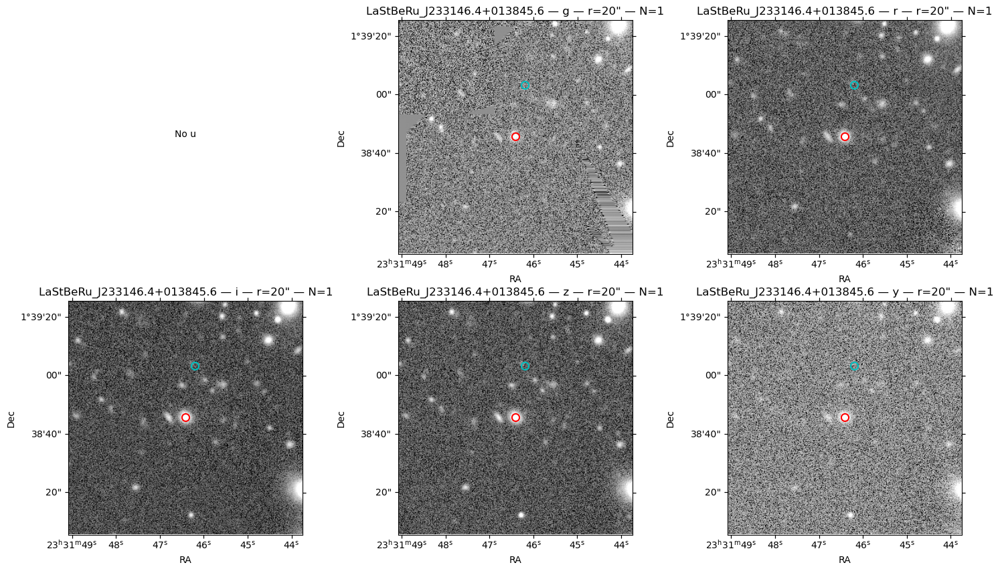

Radio: 20" | DiaObjects encontrados: 1
          diaObjectId  sep_arcsec
0  770736829069525089    0.045821


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


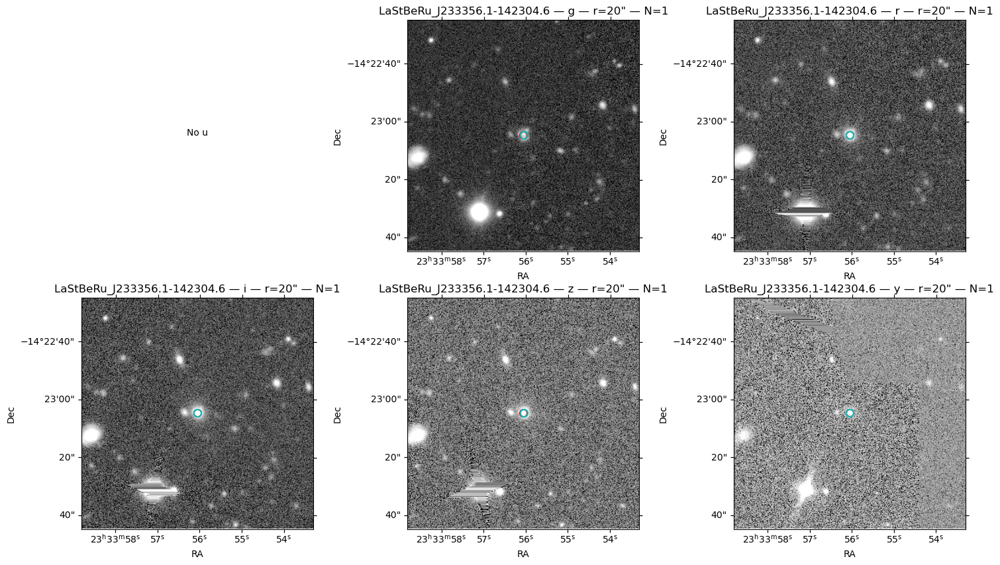

Radio: 20" | DiaObjects encontrados: 3
          diaObjectId  sep_arcsec
2  787290320223076501    0.524840
0  787290320223076580    9.188719
1  787290320223076449    9.573265


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


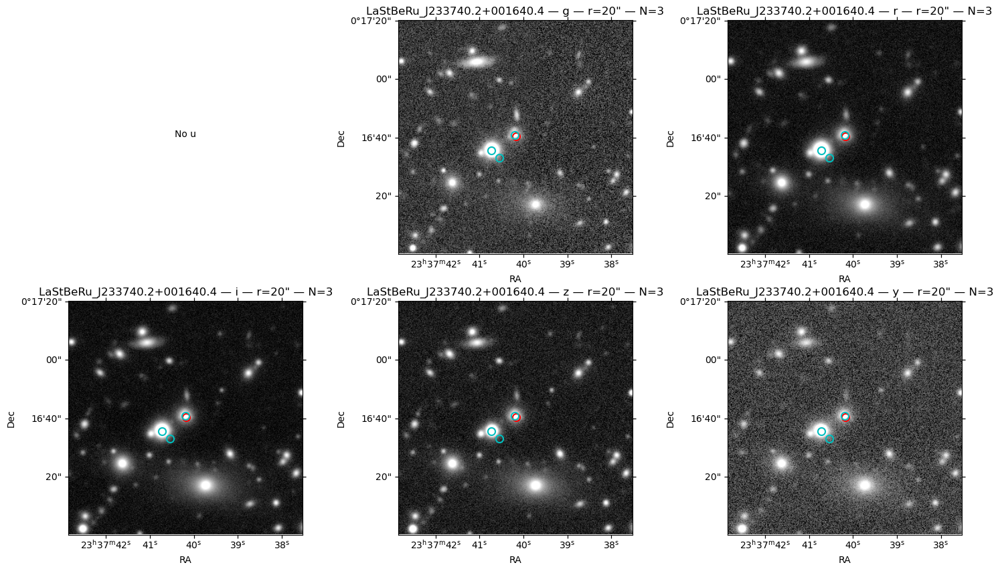

Radio: 20" | DiaObjects encontrados: 0


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


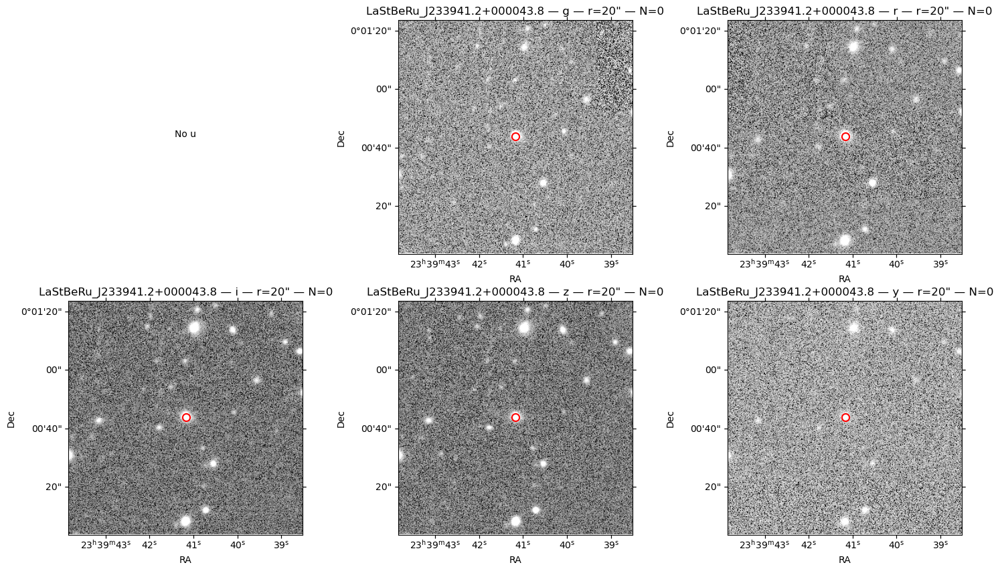

Radio: 20" | DiaObjects encontrados: 0


/tmp/ipykernel_43639/2282387835.py:71: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


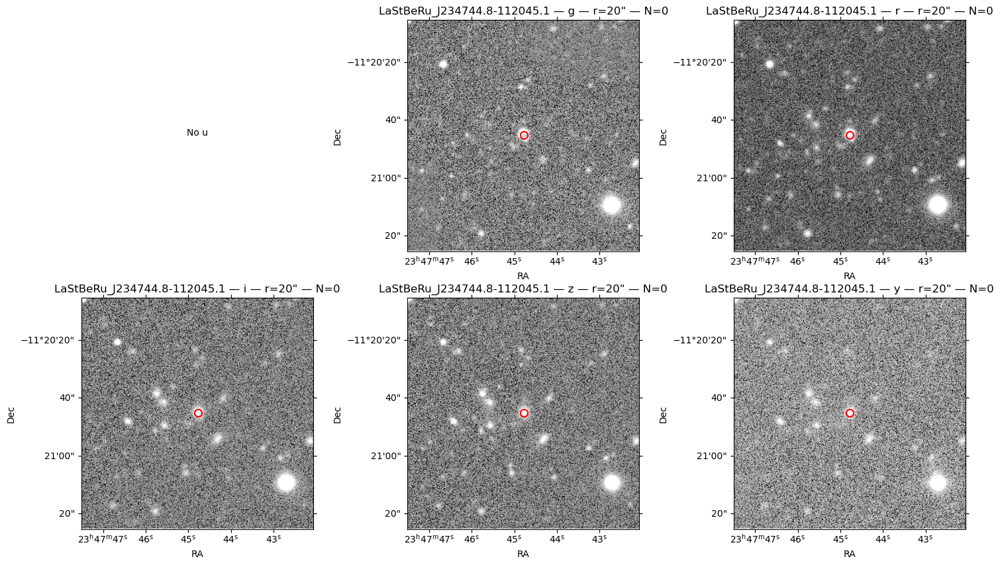

In [61]:
import numpy as np, matplotlib.pyplot as plt, astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.visualization import ImageNormalize, AsinhStretch
from astropy.wcs.utils import proj_plane_pixel_scales
from lsst.daf.butler import Butler

import matplotlib.pyplot as plt
obj = list(objects_by_target.values())
plt.hist([len(o) for o in obj], density=True)
plt.xlabel("Number of DiaObjects nearby match")
plt.ylabel("Number of systems")
plt.title("Objects nearby StrongLensing systems ")
obj_val = [len(o) for o in obj]
pd.Series(obj_val).value_counts()
lastberu = pd.read_csv("LaStBeRu_watchlist_LSST_grades.csv")
lastberu.head()
lsb_match = lastberu[lastberu["object_id"].isin(objects_by_target.keys())]
lsb_match=lastberu[lastberu["object_id"].isin(objects_by_target)].copy()
lsb_match["dia_objects"]=lsb_match["object_id"].map(objects_by_target)
lsb_match["vetting_grade"] = lsb_match["extra_info"].str[14]
lsb_match["vetting_grade"].hist()


# target_name="OGLE-2025-BLG-0451"; ra_deg,dec_deg=ra, dec
cutout_size_arcsec=80
search_radius_arcsec=20  # →
radius_deg=search_radius_arcsec/3600


butler=Butler("dp2",collections="dp2")
for i, match in A_matchs.iterrows():
    target_name = match["object_id"]
    ra_deg,dec_deg=match.ra, match.dec
    coord=SkyCoord(ra_deg*u.deg,dec_deg*u.deg)
    fig=plt.figure(figsize=(18,10))
    query=f"""
    SELECT diaObjectId,ra,dec
    FROM {DIA_OBJECT_TABLE}
    WHERE CONTAINS(
    POINT('ICRS',ra,dec),
    CIRCLE('ICRS',{ra_deg:.15g},{dec_deg:.15g},{radius_deg:.15g})
    )=1
    """
    dia_job=tap_service.submit_job(query); dia_job.run(); dia_job.wait(phases=["COMPLETED","ERROR"])
    if dia_job.phase=="ERROR": dia_job.raise_if_error()
    objects=dia_job.fetch_result().to_table().to_pandas()
    
    if len(objects)>0:
        objcoords=SkyCoord(objects.ra.values*u.deg,objects.dec.values*u.deg)
        objects["sep_arcsec"]=coord.separation(objcoords).arcsec
    
    print(f"Radio: {search_radius_arcsec}\" | DiaObjects finded: {len(objects)}")
    if len(objects)>0: print(objects[["diaObjectId","sep_arcsec"]].sort_values("sep_arcsec"))
    
    refs=list(butler.query_datasets("deep_coadd",where="patch.region OVERLAPS POINT(:ra,:dec)",bind={"ra":ra_deg,"dec":dec_deg}))
    
    for i,band in enumerate("ugrizy",1):
        sel=None
        for ref in refs:
            if str(ref.dataId.get("band",""))!=band: continue
            coadd=butler.get(ref); wcs=coadd.fits_wcs
            x,y=wcs.world_to_pixel(coord); img=np.asarray(coadd.image.array,float); h,w=img.shape
            if 0<=x<w and 0<=y<h: sel=(wcs,x,y,img,h,w); break
    
        if sel is None:
            ax=fig.add_subplot(2,3,i); ax.text(.5,.5,f"No {band}",ha="center"); ax.axis("off"); continue
    
        wcs,x,y,img,h,w=sel
        pixscale=np.mean(proj_plane_pixel_scales(wcs))*3600
        hs=int((cutout_size_arcsec/pixscale)/2)
        x0,x1=max(0,int(x)-hs),min(w,int(x)+hs); y0,y1=max(0,int(y)-hs),min(h,int(y)+hs)
        cut=img[y0:y1,x0:x1]; f=cut[np.isfinite(cut)]
        if len(f)==0: continue
    
        vmin,vmax=np.percentile(f,[5,99.5])
        ax=fig.add_subplot(2,3,i,projection=wcs)
        ax.imshow(cut,origin="lower",cmap="gray",extent=[x0,x1,y0,y1],norm=ImageNormalize(vmin=vmin,vmax=vmax,stretch=AsinhStretch(.08)))
        ax.plot(x,y,"ro",ms=8,mfc="none",mew=1.5)
    
        for _,row in objects.iterrows():
            xd,yd=wcs.world_to_pixel(SkyCoord(row.ra*u.deg,row.dec*u.deg))
            ax.plot(xd,yd,"co",ms=8,mfc="none",mew=1.5)
    
        ax.set_xlim(x0,x1); ax.set_ylim(y0,y1)
        ax.set_title(f"{target_name} — {band} — r={search_radius_arcsec}\" — N={len(objects)}")
        ax.coords[0].set_axislabel("RA"); ax.coords[1].set_axislabel("Dec")
    
    plt.tight_layout(); plt.show()

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt, astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.visualization import ImageNormalize, AsinhStretch
from astropy.wcs.utils import proj_plane_pixel_scales
from matplotlib.patches import Circle
from lsst.daf.butler import Butler

cutout_size_arcsec=80
search_radius_arcsec=40
radius_deg=search_radius_arcsec/3600
outdir="cutouts"
os.makedirs(outdir,exist_ok=True)

butler=Butler("dp2",collections="dp2")

def plot_target(match):
    target_name=match["object_id"]; ra_deg,dec_deg=match.ra,match.dec
    coord=SkyCoord(ra_deg*u.deg,dec_deg*u.deg)

    query=f"""SELECT diaObjectId,ra,dec FROM {DIA_OBJECT_TABLE}
    WHERE CONTAINS(POINT('ICRS',ra,dec),
    CIRCLE('ICRS',{ra_deg:.15g},{dec_deg:.15g},{radius_deg:.15g}))=1"""

    job=tap_service.submit_job(query); job.run(); job.wait(phases=["COMPLETED","ERROR"])
    if job.phase=="ERROR": job.raise_if_error()
    objects=job.fetch_result().to_table().to_pandas()

    refs=list(butler.query_datasets("deep_coadd",
        where="patch.region OVERLAPS POINT(:ra,:dec)",
        bind={"ra":ra_deg,"dec":dec_deg}))

    fig=plt.figure(figsize=(18,10))

    for j,band in enumerate("ugrizy",1):
        sel=None
        for ref in refs:
            if str(ref.dataId.get("band",""))!=band: continue
            coadd=butler.get(ref); wcs=coadd.fits_wcs
            x,y=wcs.world_to_pixel(coord); img=np.asarray(coadd.image.array,float); h,w=img.shape
            if 0<=x<w and 0<=y<h: sel=(wcs,x,y,img,h,w); break

        if sel is None:
            ax=fig.add_subplot(2,3,j); ax.text(.5,.5,f"No {band}",ha="center"); ax.axis("off"); continue

        wcs,x,y,img,h,w=sel
        pixscale=np.mean(proj_plane_pixel_scales(wcs))*3600
        hs=int(cutout_size_arcsec/(2*pixscale))
        r_pix=search_radius_arcsec/pixscale

        x0,x1=max(0,int(x)-hs),min(w,int(x)+hs)
        y0,y1=max(0,int(y)-hs),min(h,int(y)+hs)

        cut=img[y0:y1,x0:x1]
        finite=cut[np.isfinite(cut)]
        if len(finite)==0: continue

        vmin,vmax=np.percentile(finite,[5,99.5])

        ax=fig.add_subplot(2,3,j,projection=wcs)
        ax.imshow(cut,origin="lower",cmap="gray",extent=[x0,x1,y0,y1],
                  norm=ImageNormalize(vmin=vmin,vmax=vmax,stretch=AsinhStretch(.08)))

        ax.plot(x,y,"ro",ms=8,mfc="none",mew=1.5)
        ax.add_patch(Circle((x,y),r_pix,edgecolor="lime",facecolor="none",lw=1.5))

        if len(objects):
            objcoords=SkyCoord(objects.ra.values*u.deg,objects.dec.values*u.deg)
            xd,yd=wcs.world_to_pixel(objcoords)
            ax.plot(xd,yd,"co",ms=8,mfc="none",mew=1.5)

        ax.set_xlim(x0,x1); ax.set_ylim(y0,y1)
        ax.set_title(f"{target_name} — {band} — r={search_radius_arcsec}\" — N={len(objects)}")
        ax.coords[0].set_axislabel("RA"); ax.coords[1].set_axislabel("Dec")

    plt.tight_layout()
    filename=os.path.join(outdir,f"{target_name}.png")
    plt.savefig(filename,dpi=150,bbox_inches="tight")
    plt.close(fig)

for _,match in A_matchs.iterrows():
    plot_target(match)

## Same with DIAObject

In [ ]:
from astropy.coordinates import SkyCoord
import astropy.units as u
from lsst.rsp import get_tap_service
import pandas as pd
import pickle
from tqdm import tqdm

tap_service = get_tap_service("tap")

DIA_OBJECT_TABLE = "dp2.Object"
RADIUS_ARCSEC = 40.0
RADIUS_DEG = RADIUS_ARCSEC / 3600.0

CSV_PATH = "lastberuXdp2_coords.csv"
PICKLE_PATH = "lastberu_objects.pkl"
BATCH_SIZE = 100

targets = pd.read_csv(CSV_PATH)
targets.columns = targets.columns.astype(str).str.strip()

target_coords = SkyCoord(
  targets["coord_ra"].to_numpy() * u.deg,
  targets["coord_dec"].to_numpy() * u.deg
)

# Guardamos temporalmente las coincidencias por índice de target
matches = {i: [] for i in range(len(targets))}

for start in tqdm(
  range(0, len(targets), BATCH_SIZE),
  desc="Consultas TAP"
):
  stop = min(start + BATCH_SIZE, len(targets))

  clauses = []
  for ra, dec in zip(
      targets["coord_ra"].iloc[start:stop],
      targets["coord_dec"].iloc[start:stop]
  ):
      clauses.append(
          f"""
          CONTAINS(
              POINT('ICRS', coord_ra, coord_dec),
              CIRCLE(
                  'ICRS',
                  {ra:.15g},
                  {dec:.15g},
                  {RADIUS_DEG:.15g}
              )
          ) = 1
          """
      )

  query = f"""
  SELECT ObjectId, coord_ra, coord_dec
  FROM {DIA_OBJECT_TABLE}
  WHERE {" OR ".join(clauses)}
  """

  job = tap_service.submit_job(query)
  job.run()
  job.wait(phases=["COMPLETED", "ERROR"])

  if job.phase == "ERROR":
      job.raise_if_error()

  batch_objects = job.fetch_result().to_table().to_pandas()

  if batch_objects.empty:
      continue

  object_coords = SkyCoord(
      batch_objects["coord_ra"].to_numpy() * u.deg,
      batch_objects["coord_dec"].to_numpy() * u.deg
  )
 
  idx_object, idx_target, separations, _ = (
      target_coords[start:stop].search_around_sky(
          object_coords,
          RADIUS_ARCSEC * u.arcsec
      )
  )

  for i_target, i_object, separation in zip(
      idx_target, idx_object, separations
  ):
      row = batch_objects.iloc[int(i_object)].to_dict()
      row["sep_arcsec"] = separation.arcsec
      matches[start + int(i_target)].append(row)

# Reconstruir el mismo diccionario target -> DataFrame
objects_by_target = {}

for i, target in targets.iterrows():
  objects_by_target[target["object_id"]] = pd.DataFrame(
      matches[i],
      columns=["ObjectId", "coord_ra", "coord_dec", "sep_arcsec"]
  )

with open(PICKLE_PATH, "wb") as f:
  pickle.dump(objects_by_target, f)

print(f"Guardado en {PICKLE_PATH}")

Consultas TAP:  12%|█▎        | 3/24 [05:21<42:18, 120.86s/it]

Radio: 20" | Objects encontrados: 37
              ObjectId  sep_arcsec
33  785663111733468621    0.166612
25  785663111733468618    3.956794
..                 ...         ...
26  785663111733468594   19.546156
3   785663111733446446   19.822094

[37 rows x 2 columns]


/tmp/ipykernel_43639/2835586976.py:88: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


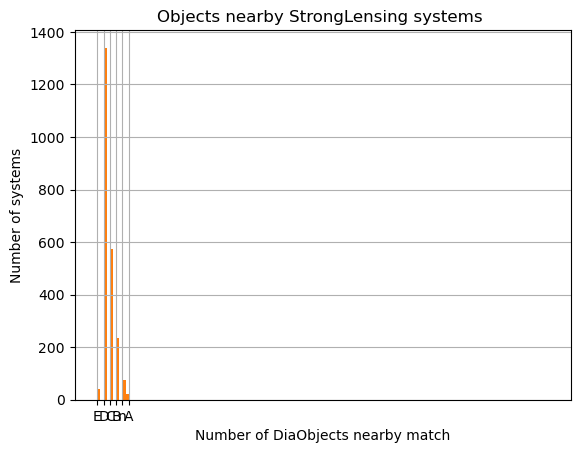

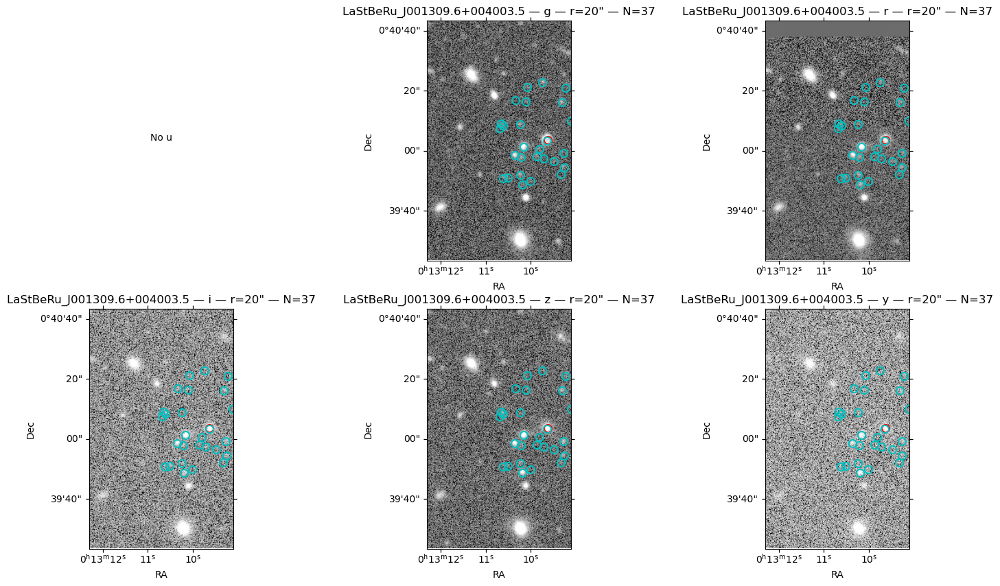

Radio: 20" | Objects encontrados: 27
              ObjectId  sep_arcsec
14  787338217698379240    0.057123
17  787338217698379243    4.817593
16  787338217698379242    4.980209
9   787338217698379244    5.053570
15  787338217698379241    5.586687
13  787338217698379239    5.858847
21  787338217698379248    6.742719
11  787338217698379237    6.942757
19  787338217698379246    6.985362
22  787338217698379249    8.352845
20  787338217698379247    9.009765
10  787338217698379236    9.855892
12  787338217698379238   10.592643
18  787338217698379245   10.674568
5   787338217698364539   14.880426
3   787338217698364528   17.283323
6   787338217698379113   17.472811
8   787338217698379110   17.616980
2   787338217698381108   17.742120
4   787338217698364537   17.767743
26  787338217698362940   18.196455
0   787338217698381833   18.383422
24  787338217698362947   19.362056
1   787338217698381107   19.583126
23  787338217698379308   19.708005
7   787338217698379108   19.719828
25  78733821769836

/tmp/ipykernel_43639/2835586976.py:88: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout(); plt.show()


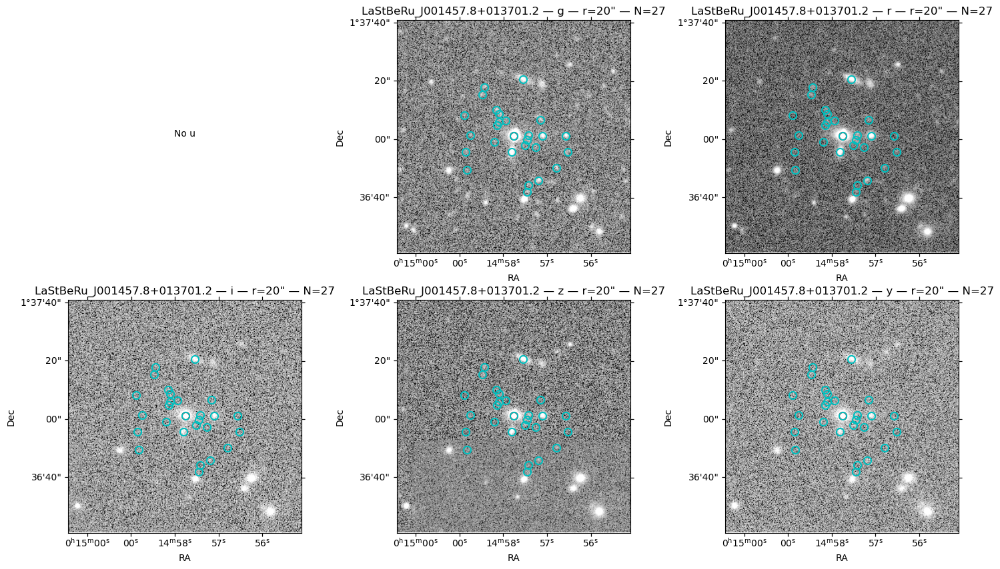

Radio: 20" | Objects encontrados: 8
             ObjectId  sep_arcsec
4  737987119321976482    0.178343
3  737987119321976483    5.699227
2  737987119321976493   11.150273
1  737987119321976494   14.348993
7  737987119321973076   15.271091
0  737987119321976495   15.941573
5  737987119321973072   16.392354
6  737987119321973082   19.391782


/tmp/ipykernel_43639/2835586976.py:88: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


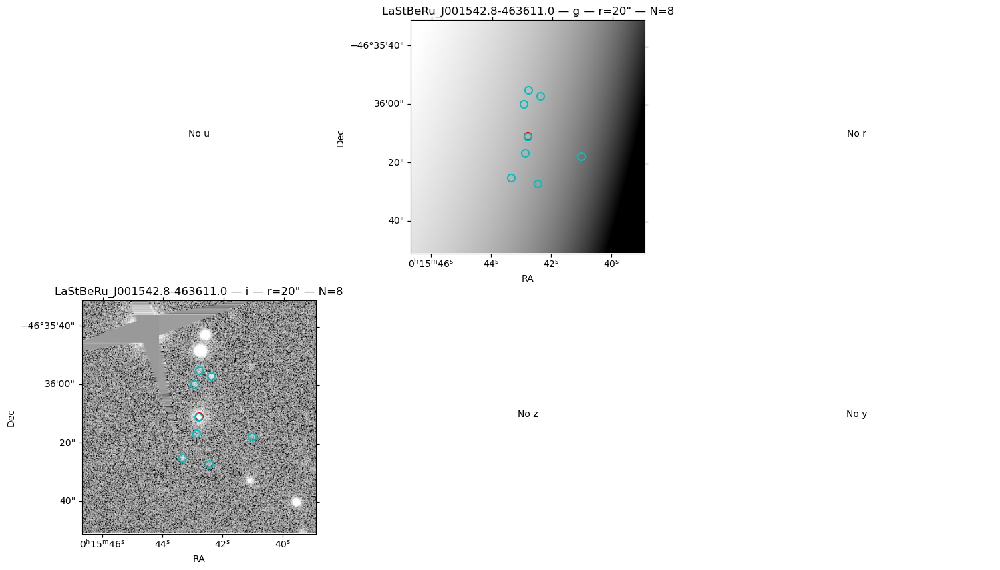

Radio: 20" | Objects encontrados: 15
              ObjectId  sep_arcsec
14  775728130823301857    0.191362
12  775728130823301859    2.973535
13  775728130823301858    3.066532
11  775728130823301860    6.006196
10  775728130823301861    6.954949
9   775728130823301862    7.593138
1   775728130823292405    8.808576
8   775728130823301874   14.693597
6   775728130823301876   14.712051
7   775728130823301875   16.535150
5   775728130823301851   17.844949
0   775728130823292399   18.182048
2   775728130823292458   18.875035
3   775728130823292455   19.202498
4   775728130823301852   19.311569


/tmp/ipykernel_43639/2835586976.py:88: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


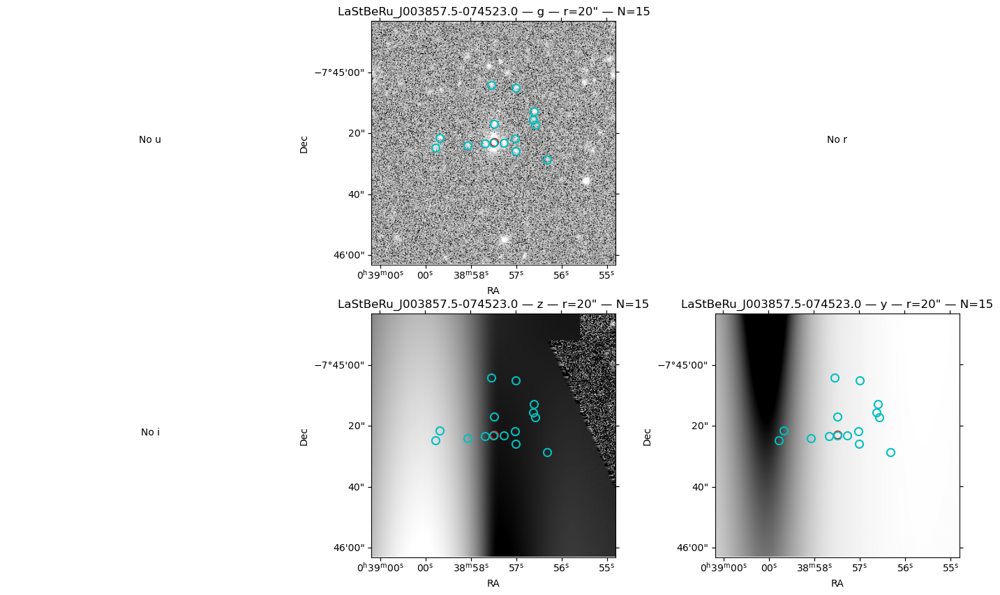

Radio: 20" | Objects encontrados: 20
              ObjectId  sep_arcsec
6   787375463654763525    0.488232
7   787375463654763526    1.605374
5   787375463654763524    6.870436
14  787375463654752865    7.586728
19  787375463654754455    9.294500
3   787375463654763522    9.692183
13  787375463654752870   10.965482
8   787375463654763536   11.343565
1   787375463654763520   12.500794
10  787375463654754159   12.658056
9   787375463654763537   13.362734
17  787375463654752919   13.875175
2   787375463654763521   14.170976
18  787375463654754462   14.499876
11  787375463654754165   15.122797
0   787375463654763519   15.582117
4   787375463654763523   15.617733
12  787375463654752847   15.846707
16  787375463654752918   17.782038
15  787375463654752926   17.787952


/tmp/ipykernel_43639/2835586976.py:88: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout(); plt.show()


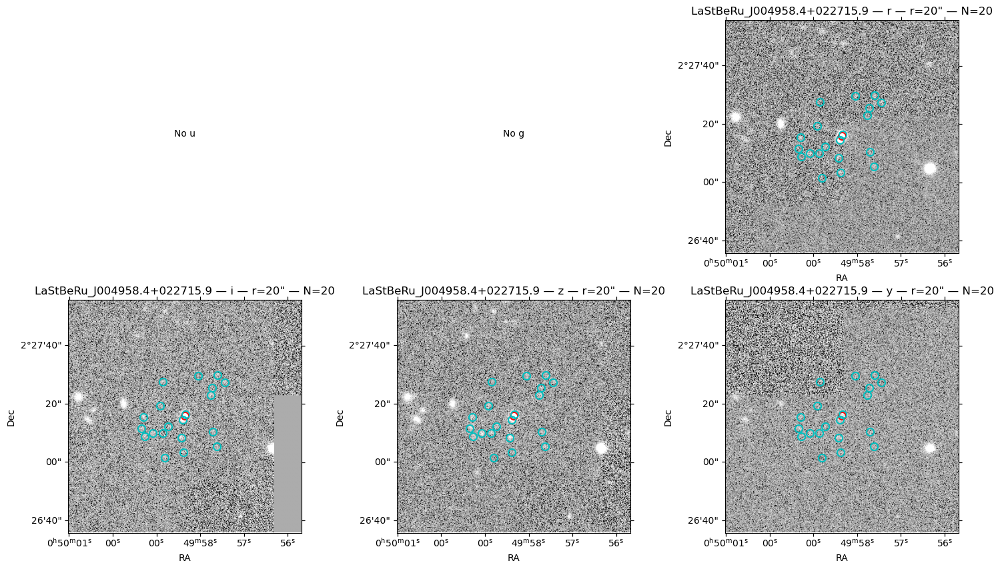

Radio: 20" | Objects encontrados: 13
              ObjectId  sep_arcsec
4   787393605596621735    0.382580
3   787393605596621734    2.386150
5   787393605596621736    2.672955
1   787393605596621732    4.496926
2   787393605596621733    6.051055
7   787393605596621738    8.751563
6   787393605596621737    8.919886
12  787393605596610840   10.314690
11  787393605596610823   11.430055
0   787393605596612600   13.503759
8   787393605596621754   15.540746
10  787393605596610855   16.213397
9   787393605596621755   19.422336


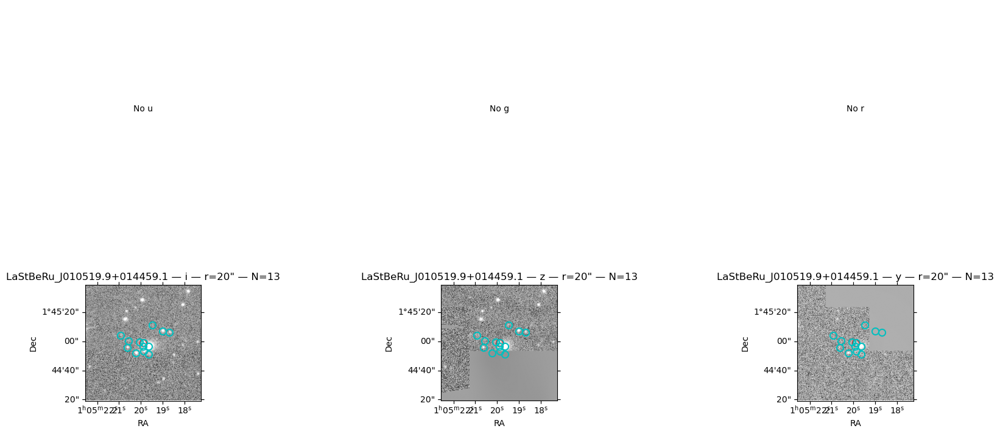

Radio: 20" | Objects encontrados: 20
              ObjectId  sep_arcsec
8   785757188697113740    0.561494
7   785757188697113741    0.854114
13  785757188697113735    7.012610
14  785757188697113743    7.449468
6   785757188697113742    7.838066
18  785757188697113745    8.194132
9   785757188697113739    8.436113
17  785757188697113746    8.956738
11  785757188697113737    9.049503
12  785757188697113736    9.535926
16  785757188697113747    9.821373
10  785757188697113738    9.829130
19  785757188697113744   11.619330
3   785757188697097731   12.078924
1   785757188697097711   12.672569
2   785757188697097740   14.546350
15  785757188697113748   15.499930
4   785757188697097838   15.591415
5   785757188697097775   17.666418
0   785757188697097859   19.669188


/tmp/ipykernel_43639/2835586976.py:88: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


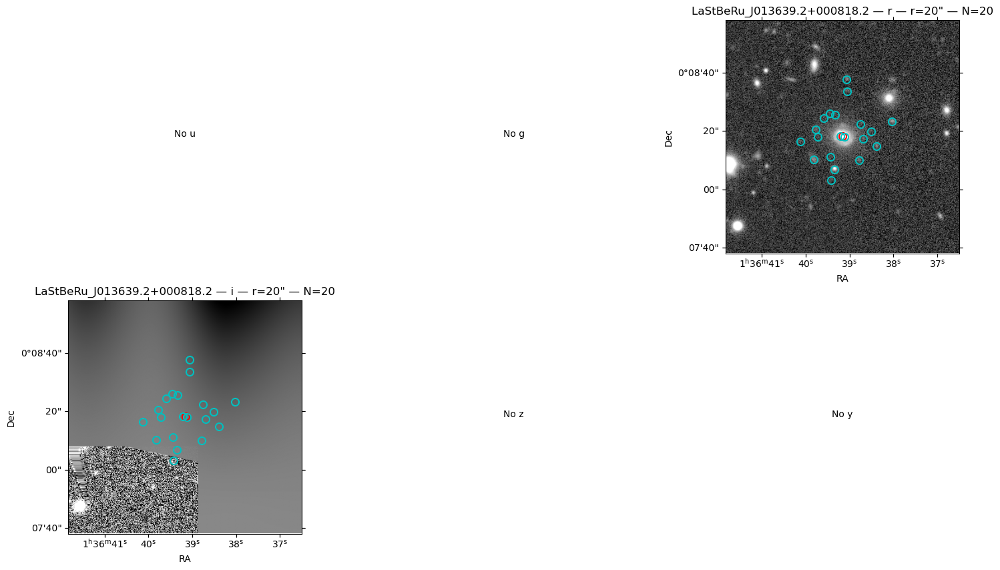

Radio: 20" | Objects encontrados: 10
             ObjectId  sep_arcsec
2  784106271988000519    0.032920
4  784106271988000517    3.141365
3  784106271988000518    5.305473
7  784106271987991601    9.631533
5  784106271987991591    9.763854
8  784106271987991595   15.834574
1  784106271988000502   16.607679
0  784106271988000503   17.517149
6  784106271987991603   17.830902
9  784106271987991632   19.185488


/tmp/ipykernel_43639/2835586976.py:88: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


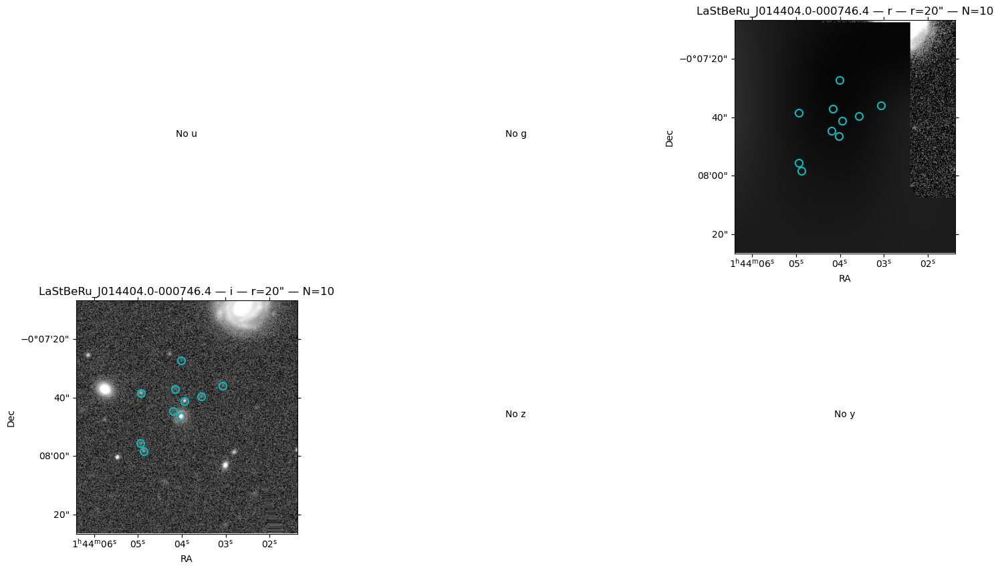

Radio: 20" | Objects encontrados: 20
              ObjectId  sep_arcsec
7   788885780314473521    0.197906
4   788885780314473526    4.985323
8   788885780314473522    5.287741
10  788885780314473524    5.747301
11  788885780314473525    6.983915
9   788885780314473523    8.000418
16  788885780314473518    8.849372
5   788885780314473519    9.078310
6   788885780314473520    9.278843
17  788885780314458789   11.152416
18  788885780314456898   11.966596
3   788885780314473479   12.620006
13  788885780314473528   12.855981
14  788885780314473516   13.887562
15  788885780314473517   14.185867
2   788885780314473478   14.613118
19  788885780314456999   15.717888
12  788885780314473527   15.794923
0   788885780314459747   19.217224
1   788885780314473644   19.367679


/tmp/ipykernel_43639/2835586976.py:88: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout(); plt.show()


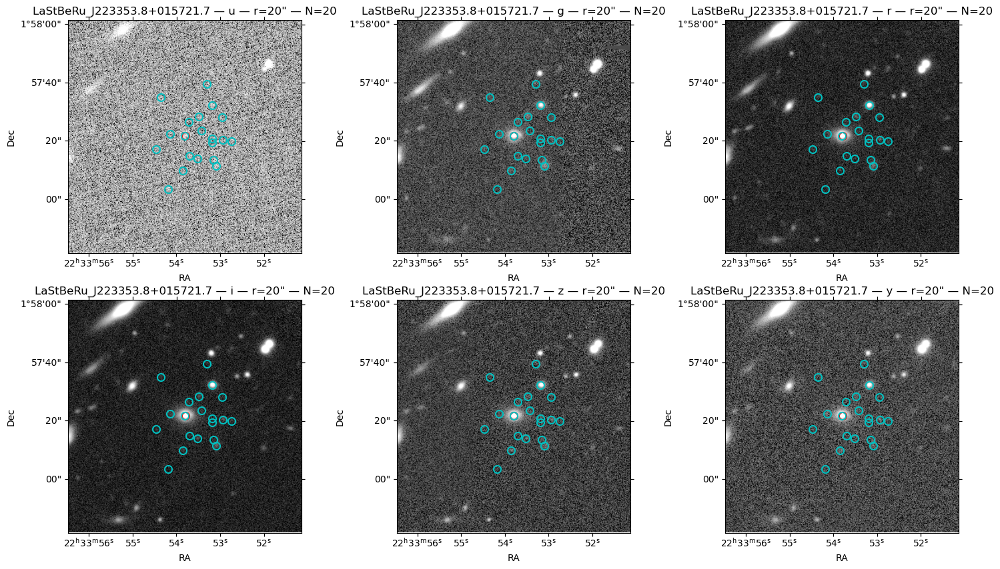

Radio: 20" | Objects encontrados: 13
              ObjectId  sep_arcsec
5   788894438968540254    0.103339
11  788894438968540255    2.158002
9   788894438968540257    5.368597
10  788894438968540256    5.865420
1   788894438968527754    7.951976
8   788894438968540258    9.885134
7   788894438968540264   12.322691
0   788894438968525811   13.280063
4   788894438968540193   13.641806
3   788894438968540194   14.481175
2   788894438968540205   18.192737
6   788894438968540265   18.896095
12  788894438968540266   18.902975


/tmp/ipykernel_43639/2835586976.py:88: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


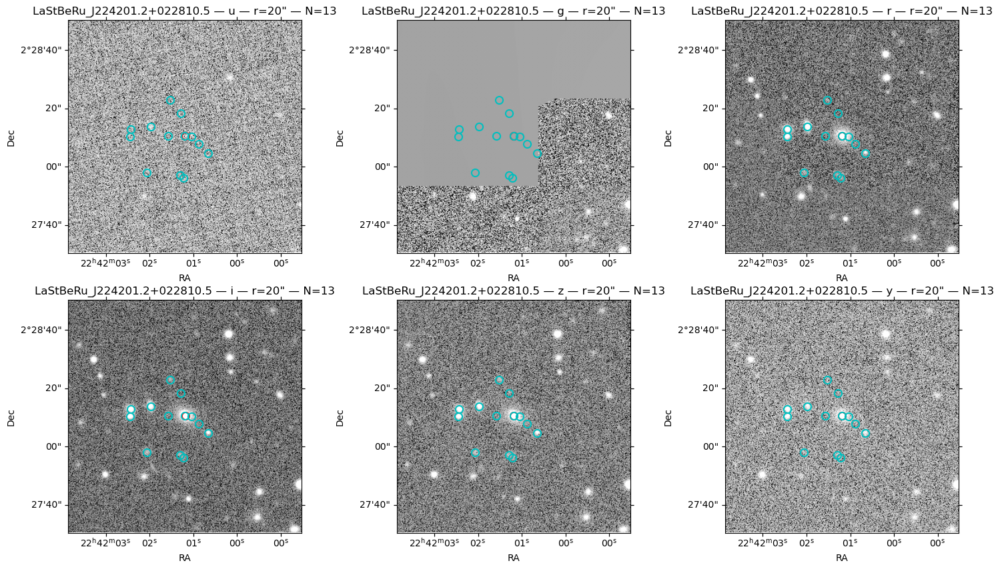

Radio: 20" | Objects encontrados: 22
              ObjectId  sep_arcsec
13  787227991657696945    0.067285
20  787227991657696952    1.488363
18  787227991657696950    1.927223
17  787227991657696949    2.092580
16  787227991657696948    3.190526
14  787227991657696946    5.671633
15  787227991657696947    5.784047
19  787227991657696951    6.688632
11  787227991657696943    6.892101
21  787227991657696953    8.467770
12  787227991657696944    9.014901
10  787227991657696954   10.790894
4   787227991657679975   11.216529
3   787227991657678710   12.411238
0   787227991657678616   12.471646
7   787227991657698359   12.909944
8   787227991657697021   14.353345
6   787227991657698358   15.542505
9   787227991657697022   16.090741
2   787227991657678632   17.746098
5   787227991657680823   17.990470
1   787227991657678599   18.110325


/tmp/ipykernel_43639/2835586976.py:88: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


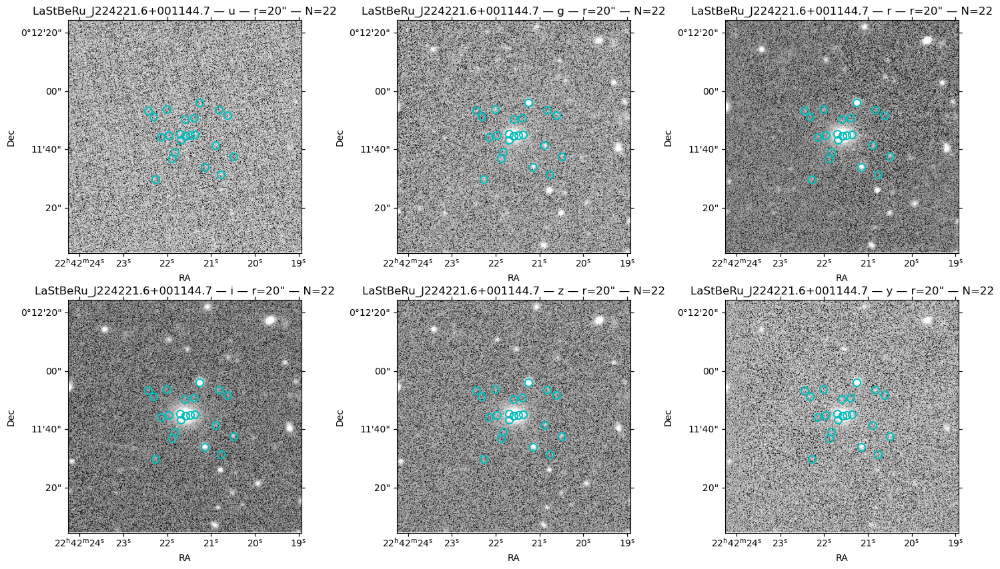

Radio: 20" | Objects encontrados: 15
              ObjectId  sep_arcsec
2   790560748840438401    0.024888
0   790560748840438403    3.365871
3   790560748840438402    3.933606
1   790560748840438400    6.777570
4   790560748840438404    6.995896
11  790560748840420928   11.885670
9   790560748840422774   14.394167
12  790560748840420941   15.158828
14  790560748840422074   15.694710
7   790560748840438396   15.762847
13  790560748840420873   15.790861
5   790560748840438335   15.901577
10  790560748840422777   18.197279
6   790560748840438336   18.375586
8   790560748840438397   19.237646


/tmp/ipykernel_43639/2835586976.py:88: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


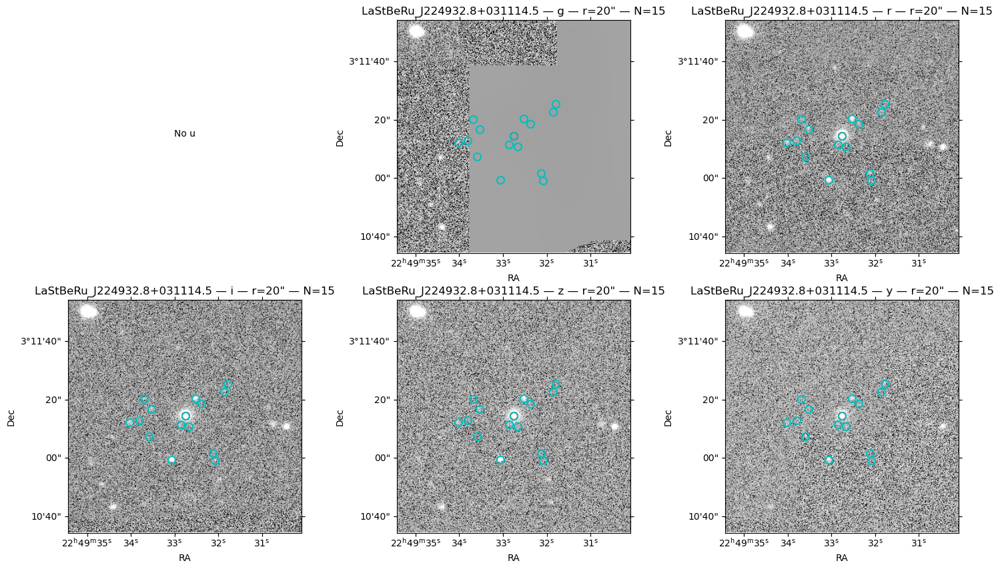

Radio: 20" | Objects encontrados: 23
              ObjectId  sep_arcsec
18  785591162441318553    0.859856
19  785591162441318552    0.905226
17  785591162441318554    1.584976
16  785591162441318555    3.415567
15  785591162441318556    9.306358
14  785591162441318557   10.304141
5   785591162441318492   10.596887
2   785591162441318495   10.921902
13  785591162441318508   11.361816
22  785591162441302821   11.698483
20  785591162441318551   12.460664
10  785591162441318573   12.993088
0   785591162441305438   13.589326
9   785591162441318574   13.811938
12  785591162441318509   13.893999
21  785591162441318550   14.331606
8   785591162441318481   15.059459
6   785591162441318491   15.097717
7   785591162441318482   16.047690
4   785591162441318493   16.115550
1   785591162441318463   18.402593
11  785591162441318527   19.055963
3   785591162441318494   19.287750


KeyboardInterrupt: 

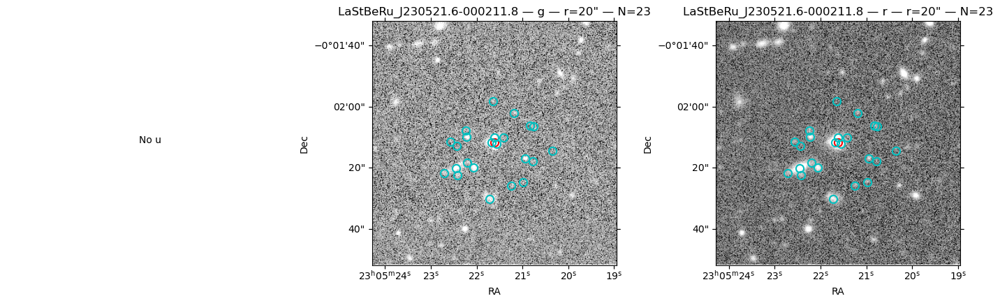

In [73]:
import numpy as np, matplotlib.pyplot as plt, astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.visualization import ImageNormalize, AsinhStretch
from astropy.wcs.utils import proj_plane_pixel_scales
from lsst.daf.butler import Butler

import matplotlib.pyplot as plt
obj = list(objects_by_target.values())
plt.hist([len(o) for o in obj], density=True)
plt.xlabel("Number of DiaObjects nearby match")
plt.ylabel("Number of systems")
plt.title("Objects nearby StrongLensing systems ")
obj_val = [len(o) for o in obj]
pd.Series(obj_val).value_counts()
lastberu = pd.read_csv("LaStBeRu_watchlist_LSST_grades.csv")
lastberu.head()
lsb_match = lastberu[lastberu["object_id"].isin(objects_by_target.keys())]
lsb_match=lastberu[lastberu["object_id"].isin(objects_by_target)].copy()
lsb_match["objects"]=lsb_match["object_id"].map(objects_by_target)
lsb_match["vetting_grade"] = lsb_match["extra_info"].str[14]
lsb_match["vetting_grade"].hist()


# target_name="OGLE-2025-BLG-0451"; ra_deg,dec_deg=ra, dec
cutout_size_arcsec=80
search_radius_arcsec=20  # →
radius_deg=search_radius_arcsec/3600


butler=Butler("dp2",collections="dp2")
for i, match in A_matchs.iterrows():
    target_name = match["object_id"]
    ra_deg,dec_deg=match.ra, match.dec
    coord=SkyCoord(ra_deg*u.deg,dec_deg*u.deg)
    fig=plt.figure(figsize=(18,10))
    query=f"""
    SELECT ObjectId,coord_ra,coord_dec
    FROM {DIA_OBJECT_TABLE}
    WHERE CONTAINS(
    POINT('ICRS',coord_ra,coord_dec),
    CIRCLE('ICRS',{ra_deg:.15g},{dec_deg:.15g},{radius_deg:.15g})
    )=1
    """
    dia_job=tap_service.submit_job(query); dia_job.run(); dia_job.wait(phases=["COMPLETED","ERROR"])
    if dia_job.phase=="ERROR": dia_job.raise_if_error()
    objects=dia_job.fetch_result().to_table().to_pandas()
    
    if len(objects)>0:
        objcoords=SkyCoord(objects.coord_ra.values*u.deg,objects.coord_dec.values*u.deg)
        objects["sep_arcsec"]=coord.separation(objcoords).arcsec
    
    print(f"Radio: {search_radius_arcsec}\" | Objects encontrados: {len(objects)}")
    if len(objects)>0: print(objects[["ObjectId","sep_arcsec"]].sort_values("sep_arcsec"))
    
    refs=list(butler.query_datasets("deep_coadd",where="patch.region OVERLAPS POINT(:ra,:dec)",bind={"ra":ra_deg,"dec":dec_deg}))
    
    for i,band in enumerate("ugrizy",1):
        sel=None
        for ref in refs:
            if str(ref.dataId.get("band",""))!=band: continue
            coadd=butler.get(ref); wcs=coadd.fits_wcs
            x,y=wcs.world_to_pixel(coord); img=np.asarray(coadd.image.array,float); h,w=img.shape
            if 0<=x<w and 0<=y<h: sel=(wcs,x,y,img,h,w); break
    
        if sel is None:
            ax=fig.add_subplot(2,3,i); ax.text(.5,.5,f"No {band}",ha="center"); ax.axis("off"); continue
    
        wcs,x,y,img,h,w=sel
        pixscale=np.mean(proj_plane_pixel_scales(wcs))*3600
        hs=int((cutout_size_arcsec/pixscale)/2)
        x0,x1=max(0,int(x)-hs),min(w,int(x)+hs); y0,y1=max(0,int(y)-hs),min(h,int(y)+hs)
        cut=img[y0:y1,x0:x1]; f=cut[np.isfinite(cut)]
        if len(f)==0: continue
    
        vmin,vmax=np.percentile(f,[5,99.5])
        ax=fig.add_subplot(2,3,i,projection=wcs)
        ax.imshow(cut,origin="lower",cmap="gray",extent=[x0,x1,y0,y1],norm=ImageNormalize(vmin=vmin,vmax=vmax,stretch=AsinhStretch(.08)))
        ax.plot(x,y,"ro",ms=8,mfc="none",mew=1.5)
    
        for _,row in objects.iterrows():
            xd,yd=wcs.world_to_pixel(SkyCoord(row.coord_ra*u.deg,row.coord_dec*u.deg))
            ax.plot(xd,yd,"co",ms=8,mfc="none",mew=1.5)
    
        ax.set_xlim(x0,x1); ax.set_ylim(y0,y1)
        ax.set_title(f"{target_name} — {band} — r={search_radius_arcsec}\" — N={len(objects)}")
        ax.coords[0].set_axislabel("RA"); ax.coords[1].set_axislabel("Dec")
    
    plt.tight_layout(); plt.show()